/var/folders/56/fjm7_ygx0933sxy82cbvkync0000gn/T/ipykernel_30186/2392688977.py:16: Pandas4Warning: 'd' is deprecated and will be removed in a future version, please use 'D' instead.
  df['Fecha'] = df['Inicio_del_viaje'].dt.floor('d')


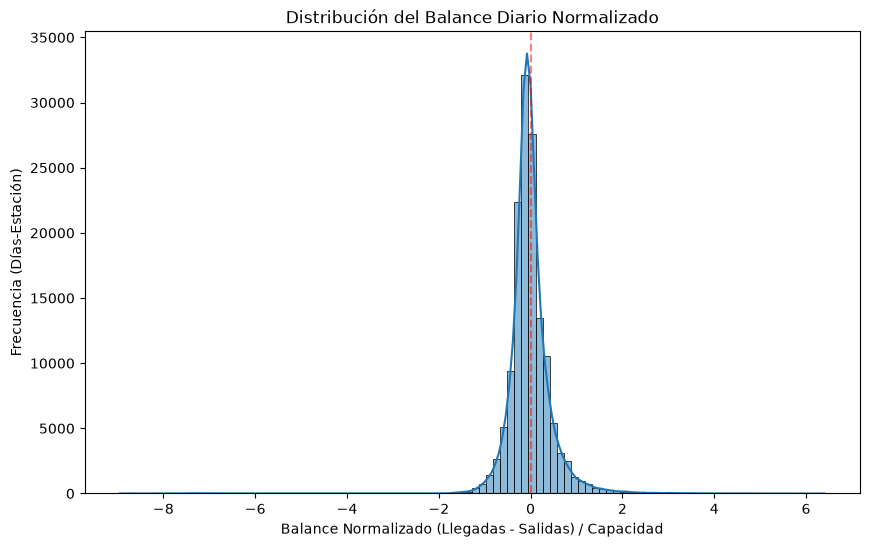

Percentiles del Balance Normalizado:
0.05   -0.600000
0.10   -0.454545
0.15   -0.333333
0.20   -0.266667
0.80    0.210526
0.85    0.315789
0.90    0.466667
0.95    0.733333
Name: Balance_Normalizado, dtype: float64


In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from mi_bici_experiment.config import INTERIM_DATA_DIR


df = pd.read_parquet(INTERIM_DATA_DIR / 'features.parquet')

df['Fecha'] = df['Inicio_del_viaje'].dt.floor('d')

salidas = df.groupby(['Fecha', 'Origen_Id']).size().reset_index(name='Salidas')
salidas.rename(columns={'Origen_Id': 'Estacion_Id'}, inplace=True)

llegadas = df.groupby(['Fecha', 'Destino_Id']).size().reset_index(name='Llegadas')
llegadas.rename(columns={'Destino_Id': 'Estacion_Id'}, inplace=True)

capacidad = df.groupby('Origen_Id')['dpcapacity'].max().reset_index()
capacidad.rename(columns={'Origen_Id': 'Estacion_Id'}, inplace=True)

# Unir Salidas y Llegadas
balance_diario = pd.merge(salidas, llegadas, on=['Fecha', 'Estacion_Id'], how='outer').fillna(0)

# Unir la capacidad de la estación
balance_diario = pd.merge(balance_diario, capacidad, on='Estacion_Id', how='left')

# Evitar división por cero si alguna estación tiene capacidad 0 o NaN
balance_diario['dpcapacity'] = balance_diario['dpcapacity'].replace(0, np.nan)

# Calcular el Balance Neto y el Balance Normalizado
balance_diario['Balance_Neto'] = balance_diario['Llegadas'] - balance_diario['Salidas']
balance_diario['Balance_Normalizado'] = balance_diario['Balance_Neto'] / balance_diario['dpcapacity']

# Limpiar valores nulos resultantes de capacidades inválidas
balance_diario = balance_diario.dropna(subset=['Balance_Normalizado'])

# Visualización de la distribución para definir umbrales
plt.figure(figsize=(10, 6))
sns.histplot(balance_diario['Balance_Normalizado'], bins=100, kde=True)
plt.title('Distribución del Balance Diario Normalizado')
plt.xlabel('Balance Normalizado (Llegadas - Salidas) / Capacidad')
plt.ylabel('Frecuencia (Días-Estación)')
plt.axvline(0, color='red', linestyle='--', alpha=0.5)
plt.show()

# Calcular percentiles clave para proponer los cortes de las clases
percentiles = balance_diario['Balance_Normalizado'].quantile([0.05, 0.10, 0.15, 0.20, 0.80, 0.85, 0.90, 0.95])
print("Percentiles del Balance Normalizado:")
print(percentiles)


En la grafica se observa que hay una distribución marcadamente leptocúrtica, con la gran mayoría de los datos concentrados muy cerca del cero. Esto indica que, a nivel diario, la mayor parte de las estaciones de MiBici logran un equilibrio natural entre llegadas y salidas, o bien, el equipo de logística del sistema es altamente eficiente rebalanceando las bicicletas.

 A partir de los percentiles podemos estructurar las reglas de negocio para las tres clases de riesgo. Utilizar los percentiles 10 y 90 es la estrategia más robusta para este caso, ya que permite aislar verdaderos escenarios de riesgo (el 20% más extremo de la operación) sin generar falsas alarmas con fluctuaciones menores.

 - Clase 0 (Riesgo de quedarse sin bicicletas): Balance_Normalizado <= -0.70
Lógica: La estación perdió el equivalente al 70% o más de su capacidad instalada en un solo día. Representa el 10% inferior de tus datos históricos.


 - Clase 1 (Riesgo Bajo / Equilibrio): -0.70 < Balance_Normalizado < 0.70
Lógica: La estación operó con entradas y salidas fluidas, manteniendo su inventario con fluctuaciones tolerables (80% de los casos).


 - Clase 2 (Riesgo de quedarse sin anclajes): Balance_Normalizado >= 0.70
Lógica: La estación acumuló un excedente de bicicletas equivalente al 70% o más de su capacidad. Representa el 10% superior de tus datos históricos.

**NOTA:** Como se observa en la grafica existen valores atípicos que superan el -2 y el +2. Matemáticamente, un balance normalizado de +2 significa que la estación recibió el doble de bicicletas de las que caben en sus anclajes. Para evitar el modelo de clasificación aprenda ruido, será necesario aplicar una regla de clipping o filtrado a estos outliers antes del entrenamiento, limitando el análisis a estaciones con operaciones lógicas.

In [53]:
def clasificacion_variable_objetivo_y_caracterizticas(balance_diario):
    balance_diario = balance_diario[(balance_diario['Balance_Normalizado'] >= -1.5) & 
                                (balance_diario['Balance_Normalizado'] <= 1.5)].copy()

    #  Creación de la variable actual de estado (0: Sin bicis, 1: Balanceado, 2: Sin anclajes)
    condiciones = [
        (balance_diario['Balance_Normalizado'] <= -0.70),
        (balance_diario['Balance_Normalizado'] >= 0.70)
    ]
    opciones = [0, 2]
    balance_diario['Estado_Actual'] = np.select(condiciones, opciones, default=1)

    # Ingeniería de Características: Variables Temporales
    balance_diario['Dia_Semana'] = balance_diario['Fecha'].dt.dayofweek
    balance_diario['Es_Fin_Semana'] = balance_diario['Dia_Semana'].isin([5, 6]).astype(int)
    balance_diario['Mes'] = balance_diario['Fecha'].dt.month

    # Construcción de la Variable Objetivo (y) para T+1
    # Ordenamos estrictamente por estación y fecha para evitar mezcla de series de tiempo
    balance_diario = balance_diario.sort_values(['Estacion_Id', 'Fecha'])

    # Desplazamos el estado un día hacia atrás dentro de cada grupo de estación
    # Esto alinea los features del "Hoy" con la clase de riesgo de "Mañana"
    balance_diario['Riesgo_T1'] = balance_diario.groupby('Estacion_Id')['Estado_Actual'].shift(-1)

    # El último día histórico de cada estación queda nulo, lo descartamos para el entrenamiento
    dataset_ml = balance_diario.dropna(subset=['Riesgo_T1']).copy()
    dataset_ml['Riesgo_T1'] = dataset_ml['Riesgo_T1'].astype(int)
    return dataset_ml


dataset_ml = clasificacion_variable_objetivo_y_caracterizticas(balance_diario)

In [54]:
def creacion_variables_memoria_historica(dataset_ml):
    # Asegurar de que el dataset esté perfectamente ordenado
    dataset_ml = dataset_ml.sort_values(['Estacion_Id', 'Fecha'])

    # Variables de Retardo (Lags)
    # ¿Cómo se comportó el balance ayer y antier?
    dataset_ml['Balance_Lag_1'] = dataset_ml.groupby('Estacion_Id')['Balance_Normalizado'].shift(1)
    dataset_ml['Balance_Lag_2'] = dataset_ml.groupby('Estacion_Id')['Balance_Normalizado'].shift(2)

    # ¿Cómo se comportó el balance el mismo día de la semana pasada?
    dataset_ml['Balance_Lag_7'] = dataset_ml.groupby('Estacion_Id')['Balance_Normalizado'].shift(7)

    # Estado categórico previo (para capturar transiciones de estado)
    dataset_ml['Estado_Lag_1'] = dataset_ml.groupby('Estacion_Id')['Estado_Actual'].shift(1)
    dataset_ml['Estado_Lag_7'] = dataset_ml.groupby('Estacion_Id')['Estado_Actual'].shift(7)

    # Ventanas Móviles (Rolling Windows)
    # Promedio del balance en los últimos 3 y 7 días (captura la tendencia suavizada)
    dataset_ml['Media_Movil_3d'] = dataset_ml.groupby('Estacion_Id')['Balance_Normalizado'].transform(
        lambda x: x.rolling(window=3, min_periods=1).mean()
    )
    dataset_ml['Media_Movil_7d'] = dataset_ml.groupby('Estacion_Id')['Balance_Normalizado'].transform(
        lambda x: x.rolling(window=7, min_periods=1).mean()
    )

    # Volatilidad en los últimos 3 días (estaciones con mucha varianza son más impredecibles)
    dataset_ml['Volatilidad_3d'] = dataset_ml.groupby('Estacion_Id')['Balance_Normalizado'].transform(
        lambda x: x.rolling(window=3, min_periods=1).std()
    ).fillna(0) # Llenamos con 0 donde no hay suficientes datos para desviación estándar

    # 3. Limpieza post-ingeniería
    # Al hacer shift(7), los primeros 7 días de cada estación quedarán con nulos en Lag_7.
    # Para entrenar modelos (como Random Forest o XGBoost), es mejor eliminar estos registros incompletos.
    dataset_ml = dataset_ml.dropna(subset=['Balance_Lag_7', 'Estado_Lag_7']).copy()

    # Convertir variables de estado a enteros tras el dropna
    dataset_ml['Estado_Lag_1'] = dataset_ml['Estado_Lag_1'].astype(int)
    dataset_ml['Estado_Lag_7'] = dataset_ml['Estado_Lag_7'].astype(int)

    print(dataset_ml[['Fecha', 'Estacion_Id', 'Balance_Lag_1', 'Media_Movil_3d', 'Riesgo_T1']].head(10))
    return dataset_ml

dataset_ml = creacion_variables_memoria_historica(dataset_ml)
print(dataset_ml.info())

          Fecha  Estacion_Id  Balance_Lag_1  Media_Movil_3d  Riesgo_T1
2568 2025-10-08            2       0.666667        0.466667          1
2934 2025-10-09            2       0.400000        0.333333          1
3302 2025-10-10            2      -0.066667       -0.022222          2
3670 2025-10-11            2      -0.400000        0.155556          2
4038 2025-10-12            2       0.933333        0.488889          1
4403 2025-10-13            2       0.933333        0.577778          1
4771 2025-10-14            2      -0.133333        0.377778          1
5139 2025-10-15            2       0.333333       -0.044444          1
5507 2025-10-16            2      -0.333333       -0.155556          1
5875 2025-10-17            2      -0.466667       -0.288889          1
<class 'pandas.DataFrame'>
Index: 136843 entries, 2568 to 141958
Data columns (total 20 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   

¿Por qué estas variables?
Lags (1, 2, 7): Ayudan al modelo a entender patrones autorregresivos. Si una estación se vació el martes pasado (Lag_7), hay una alta probabilidad de que siga la misma dinámica este martes.
Medias Móviles (3d, 7d): Suavizan los picos atípicos. Si el balance de ayer fue excepcionalmente alto, la media de 7 días le indica al modelo la verdadera "línea base" de esa estación en la semana.
Volatilidad (3d):  Las estaciones con alta desviación estándar son erráticas; las de baja desviación son muy predecibles. Esto ayuda al modelo a ajustar su umbral de certidumbre.

In [55]:
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors

def creacion_variables_geoespaciales(dataset_ml, df):
    # Extraer el catálogo estático de estaciones con sus coordenadas
    # df es dataframe original crudo
    estaciones_geo = df[['Origen_Id', 'latitude', 'longitude']].drop_duplicates()
    estaciones_geo = estaciones_geo.rename(columns={'Origen_Id': 'Estacion_Id'}).dropna()
    print(dataset_ml.info())
    print(dataset_ml.info())
    # 2. Macro-arquitectura: Creación de Clústeres Urbanos (Zonas)
    # Agrupamos las estaciones en 10 zonas geográficas distintas
    kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)
    estaciones_geo['Zona_Espacial'] = kmeans.fit_predict(estaciones_geo[['latitude', 'longitude']])

    # 3. Micro-resiliencia: Densidad de red (Estaciones a menos de ~500 metros)
    # Convertimos coordenadas a radianes para usar la fórmula Haversine (distancia real en esfera)
    coords_rad = np.radians(estaciones_geo[['latitude', 'longitude']])

    # Radio de la Tierra ~6371 km. Buscamos vecinos en 0.5 km (500 metros).
    radio_radianes = 0.5 / 6371.0 
    nn = NearestNeighbors(radius=radio_radianes, metric='haversine')
    nn.fit(coords_rad)

    # Calculamos cuántas estaciones caen en ese radio (restando 1 para excluir la estación misma)
    vecinos = nn.radius_neighbors(coords_rad, return_distance=False)
    estaciones_geo['Densidad_500m'] = [len(v) - 1 for v in vecinos]

    # 4. Consolidación de la Arquitectura de Datos
    # Unimos estas características estáticas al dataset histórico de Machine Learning
    dataset_ml = pd.merge(dataset_ml, estaciones_geo, on='Estacion_Id', how='left')

    # Verificamos la matriz final
    print(dataset_ml[['Estacion_Id', 'Zona_Espacial', 'Densidad_500m', 'Balance_Lag_1', 'Riesgo_T1']].head())
    return dataset_ml

dataset_ml = creacion_variables_geoespaciales(dataset_ml, df)

<class 'pandas.DataFrame'>
Index: 136843 entries, 2568 to 141958
Data columns (total 20 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   Fecha                136843 non-null  datetime64[us]
 1   Estacion_Id          136843 non-null  int64         
 2   Salidas              136843 non-null  float64       
 3   Llegadas             136843 non-null  float64       
 4   dpcapacity           136843 non-null  float64       
 5   Balance_Neto         136843 non-null  float64       
 6   Balance_Normalizado  136843 non-null  float64       
 7   Estado_Actual        136843 non-null  int64         
 8   Dia_Semana           136843 non-null  int32         
 9   Es_Fin_Semana        136843 non-null  int64         
 10  Mes                  136843 non-null  int32         
 11  Riesgo_T1            136843 non-null  int64         
 12  Balance_Lag_1        136843 non-null  float64       
 13  Balance_Lag_2        136843

Reporte de Clasificación (Baseline Multinomial):
                  precision    recall  f1-score   support

   Sin Bicis (0)       0.05      0.62      0.09        81
  Balanceado (1)       1.00      0.85      0.92     39304
Sin Anclajes (2)       0.24      0.92      0.38      1668

        accuracy                           0.85     41053
       macro avg       0.43      0.80      0.46     41053
    weighted avg       0.96      0.85      0.89     41053



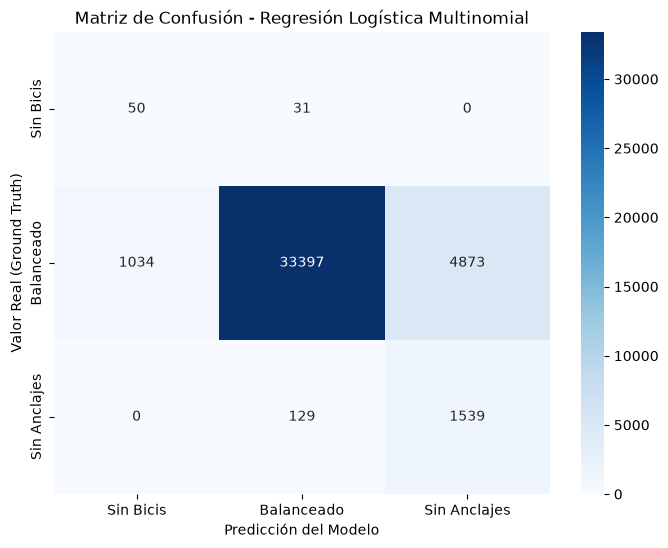

In [59]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix

def regresion_lineal_multinomial(dataset_ml):
    features = [
        'dpcapacity', 'Dia_Semana', 'Es_Fin_Semana', 'Mes', 
        'Balance_Lag_1', 'Balance_Lag_2', 'Balance_Lag_7',
        'Estado_Lag_1', 'Estado_Lag_7', 
        'Media_Movil_3d', 'Media_Movil_7d', 'Volatilidad_3d',
        'Zona_Espacial', 'Densidad_500m'
    ]

    X = dataset_ml[features]
    y = dataset_ml['Riesgo_T1']

    # 2. Separación Cronológica (Train/Test Split)
    # No usamos shuffle=True. Tomamos el 80% histórico para entrenar y el 20% más reciente para probar.
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, shuffle=False)

    # Construcción del Pipeline de Machine Learning
    # El pipeline garantiza que la estandarización se ajuste solo con los datos de entrenamiento
    pipeline_lr = Pipeline([
        ('scaler', StandardScaler()),
        ('clasificador', LogisticRegression(
            max_iter=1000, # Incrementado para asegurar convergencia con múltiples variables
            class_weight='balanced', # Crucial si la clase 1 (balanceado) domina la distribución
            random_state=42
        ))
    ])

    # 4. Entrenamiento del Modelo
    pipeline_lr.fit(X_train, y_train)

    # 5. Predicción y Evaluación
    y_pred = pipeline_lr.predict(X_test)

    print("Reporte de Clasificación (Baseline Multinomial):")
    print(classification_report(y_test, y_pred, target_names=['Sin Bicis (0)', 'Balanceado (1)', 'Sin Anclajes (2)']))

    # 6. Visualización de la Matriz de Confusión
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Sin Bicis', 'Balanceado', 'Sin Anclajes'],
                yticklabels=['Sin Bicis', 'Balanceado', 'Sin Anclajes'])
    plt.title('Matriz de Confusión - Regresión Logística Multinomial')
    plt.xlabel('Predicción del Modelo')
    plt.ylabel('Valor Real (Ground Truth)')
    plt.show()

regresion_lineal_multinomial(dataset_ml)